# Capstone · Stage 3 — Product recommendation for Kestrel Bay Capital

*Skill from Part 3: match products to the client's objectives, and prove the new allocation respects every constraint.*

Stages 1–2 found that Technology carries half the risk, that the portfolio loses about 1.9% for every +100 bp of rates,
and that the client holds no Energy. This stage builds a better allocation **systematically** instead of by intuition:

1. Map each building block to a product and the objective it serves → `figures/s3_table_products.tex`
2. List **every** allocation in 5% steps that respects the client's rules
3. Screen them on expected return and risk → `figures/s3_fig_frontier.pdf`
4. Simulate the shortlist over 5,000 years and apply a selection rule fixed in advance (option A)
5. Check whether the gain is real; add a safety-first alternative (option B)
6. **Validate** on 5,000 *new* simulated years the choice never saw → `figures/s3_table_validation.tex`
7. Choose between A and B → `figures/s3_table_decision.tex`
8. Recommended allocation, products and trades → `figures/s3_table_allocation.tex`, `figures/s3_fig_allocation.pdf`
9. Check on the actual year and key findings

**Selection rule (fixed before looking at results):** among allocations that respect all client rules, keep those whose
chance of breaching the 10% drawdown limit is *no higher than today's*; recommend the one with the highest median return.

## 1. Setup and products

In [1]:
import itertools
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, "src")
from generate_data import SECTORS, SECTOR_PARAMS
from portfolio_simulation import ASSETS, WEEKS_PER_YEAR, run_policy, simulate_years, yearly_metrics

DATA_DIR, FIGURES_DIR = Path("data"), Path("figures")
FIGURES_DIR.mkdir(exist_ok=True)
client_profile = json.loads((DATA_DIR / "client_profile.json").read_text())
market = pd.read_csv(DATA_DIR / "market_weekly.csv")
CURRENT_WEIGHTS = np.array([client_profile["allocation_pct"][asset] for asset in ASSETS], dtype=float) / 100

# Client rules (client_profile.json)
MAX_SECTOR, MIN_CASH, MAX_CASH = 0.40, 0.05, 0.20
MIN_SUSTAINABLE = 0.15                # at least 15% in renewable / ESG assets
RETURN_TARGET_PCT, DRAWDOWN_LIMIT_PCT = 6.0, -10.0
N_SIMULATED_YEARS = 5000
SELECTION_SEED, VALIDATION_SEED = 7, 2026      # 7 = the same years as Stage 2; 2026 = fresh years

# Two-series palette (validated: lightness, chroma, colour-blind separation, normal-vision floor)
CURRENT_COLOR, RECOMMENDED_COLOR = "#D9822B", "#2A55B0"
TEXT_COLOR, MUTED_COLOR = "#222222", "#666666"
plt.rcParams.update({"font.size": 9.5, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#BBBBBB", "xtick.color": MUTED_COLOR, "ytick.color": MUTED_COLOR})


def to_latex_number(value, number_format="{:.1f}", show_sign=False):
    """Format a number for a LaTeX table, using a proper minus sign."""
    if show_sign:
        number_format = "{:+" + number_format[2:]
    return number_format.format(value).replace("-", r"\textminus{}")

In [2]:
# Building block -> product (Product Alignment Guide categories) -> client objective it serves
true_rate_sensitivity = {sector: SECTOR_PARAMS[sector][2] for sector in SECTORS}
products = pd.DataFrame({
    "Product": ["Broad technology ETF", "Healthcare sector ETF", "Financials sector ETF", "Energy sector ETF",
                "Clean-energy (green) ETF", "Listed REIT fund", "Money-market fund / T-bills"],
    "Main role": ["Core growth", "Defensive anchor; risk-off destination", "Gains when rates rise; diversifier",
                  "Gains when rates rise; geopolitical hedge", "Sustainability objective; growth",
                  "Income; long-term stability", "Liquidity; risk-off buffer"],
    "Move per +25 bp (%)": [true_rate_sensitivity[s] for s in SECTORS] + [0.0],
}, index=ASSETS)
products

table_lines = [r"\begin{tabular}{@{}lllr@{}}", r"\toprule",
               r"\textbf{Building block} & \textbf{Product} & \textbf{Main role} & \textbf{Per +25 bp} \\", r"\midrule"]
for asset, row in products.iterrows():
    table_lines.append(f"{asset} & {row['Product']} & {row['Main role']} & "
                       + to_latex_number(row["Move per +25 bp (%)"], "{:.1f}", show_sign=True) + r"\% \\")
table_lines += [r"\bottomrule", r"\end{tabular}"]
(FIGURES_DIR / "s3_table_products.tex").write_text("\n".join(table_lines))
products

,Product,Main role,Move per +25 bp (%)
Technology,Broad technology ETF,Core growth,-0.8
Healthcare,Healthcare sector ETF,Defensive anchor; risk-off destination,-0.1
Financials,Financials sector ETF,Gains when rates rise; diversifier,0.6
Energy,Energy sector ETF,Gains when rates rise; geopolitical hedge,0.3
Renewable Energy,Clean-energy (green) ETF,Sustainability objective; growth,-1.0
Real Estate,Listed REIT fund,Income; long-term stability,-0.9
Cash,Money-market fund / T-bills,Liquidity; risk-off buffer,0.0


Derivatives were considered (for example a protective put on the technology ETF) but are not modelled here: the
client's rules exclude leverage, and the analysis stays within products the market model can price honestly.

## 2. Every allocation that respects the client's rules

Weights move in 5% steps. Rules: each sector 0–40%, cash 5–20%, Renewable Energy at least 15%, fully invested, no leverage.

In [3]:
STEP = 0.05
units_per_sector = np.arange(0, int(MAX_SECTOR / STEP) + 1)                 # 0, 1, ..., 8  ->  0% ... 40%
sector_units = np.array(list(itertools.product(units_per_sector, repeat=len(SECTORS))), dtype=np.int16)
cash_units = int(1 / STEP) - sector_units.sum(axis=1)
renewable_position = ASSETS.index("Renewable Energy")
respects_rules = ((cash_units >= MIN_CASH / STEP) & (cash_units <= MAX_CASH / STEP)
                  & (sector_units[:, renewable_position] >= MIN_SUSTAINABLE / STEP))
candidate_weights = np.column_stack([sector_units[respects_rules], cash_units[respects_rules]]) * STEP
print(f"{len(sector_units):,} combinations checked -> {len(candidate_weights):,} respect every client rule")
assert np.any(np.all(np.isclose(candidate_weights, CURRENT_WEIGHTS), axis=1)), "today's allocation must be a candidate"

531,441 combinations checked -> 40,840 respect every client rule


## 3. Screen on expected return and risk

Expected weekly returns and their covariance are measured on the 5,000 simulated years (including cash, which earns the
policy rate). This is a fast first filter; the real test is the full simulation in step 4.

In [4]:
simulated_returns, simulated_rates, simulated_vix = simulate_years(N_SIMULATED_YEARS, seed=SELECTION_SEED)
weekly_asset_returns = np.concatenate(
    [simulated_returns.reshape(-1, len(SECTORS)), simulated_rates.reshape(-1, 1) / WEEKS_PER_YEAR], axis=1)
mean_weekly = weekly_asset_returns.mean(axis=0)
covariance_weekly = np.cov(weekly_asset_returns, rowvar=False)

expected_return = candidate_weights @ mean_weekly * WEEKS_PER_YEAR
expected_volatility = np.sqrt(np.einsum("ij,jk,ik->i", candidate_weights, covariance_weekly, candidate_weights)
                              * WEEKS_PER_YEAR)
current_return = CURRENT_WEIGHTS @ mean_weekly * WEEKS_PER_YEAR
current_volatility = np.sqrt(CURRENT_WEIGHTS @ covariance_weekly @ CURRENT_WEIGHTS * WEEKS_PER_YEAR)

# Shortlist: no more volatile than today, highest expected return first
SHORTLIST_SIZE = 40
no_riskier = np.where(expected_volatility <= current_volatility + 1e-12)[0]
shortlist = no_riskier[np.argsort(-expected_return[no_riskier])][:SHORTLIST_SIZE]
print(f"Today: expected return {current_return:.2f}%, volatility {current_volatility:.2f}%")
print(f"{len(no_riskier):,} candidates are no more volatile than today; shortlist of {len(shortlist)} "
      f"with expected returns {expected_return[shortlist].min():.2f}% to {expected_return[shortlist].max():.2f}%")

Today: expected return 13.02%, volatility 10.06%
17,494 candidates are no more volatile than today; shortlist of 40 with expected returns 12.94% to 13.06%


## 4. Full simulation of the shortlist and the selection rule

Each shortlisted allocation is run through the same 5,000 years with monthly rebalancing (trading costs included),
and so is today's allocation. Same years for everyone, so differences come from the allocation, not from luck.

In [5]:
def simulate_allocation(weights, policy, returns, rates, vix):
    weekly_returns, _, turnover = run_policy(returns, rates, vix, policy, weights)
    annual_return, _, max_drawdown = yearly_metrics(weekly_returns)
    summary = {"Median return (%)": np.median(annual_return),
               "Chance of missing 6% target (%)": 100 * (annual_return < RETURN_TARGET_PCT).mean(),
               "Median max drawdown (%)": np.median(max_drawdown),
               "Chance of breaching 10% drawdown (%)": 100 * (max_drawdown < DRAWDOWN_LIMIT_PCT).mean()}
    return summary, annual_return, max_drawdown


def describe(weights):
    return " / ".join(f"{100 * w:.0f}" for w in weights)


today_summary, _, _ = simulate_allocation(CURRENT_WEIGHTS, "Monthly rebalance",
                                          simulated_returns, simulated_rates, simulated_vix)
shortlist_results = pd.DataFrame(
    [simulate_allocation(candidate_weights[i], "Monthly rebalance", simulated_returns, simulated_rates, simulated_vix)[0]
     for i in shortlist], index=shortlist)
shortlist_results["Allocation (" + " / ".join(ASSETS) + ")"] = [describe(candidate_weights[i]) for i in shortlist]

# Selection rule, as fixed at the top of the notebook
at_least_as_safe = shortlist_results[shortlist_results["Chance of breaching 10% drawdown (%)"]
                                     <= today_summary["Chance of breaching 10% drawdown (%)"]]
assert len(at_least_as_safe) > 0, "no shortlisted allocation is at least as safe as today"
option_a_index = at_least_as_safe["Median return (%)"].idxmax()
OPTION_A_WEIGHTS = candidate_weights[option_a_index]
print(f"{len(at_least_as_safe)} of {len(shortlist)} shortlisted allocations are at least as safe as today")
print("Today    :", describe(CURRENT_WEIGHTS), {k: round(v, 2) for k, v in today_summary.items()})
print("Option A :", describe(OPTION_A_WEIGHTS), "  (the rule fixed in advance)")
shortlist_results.sort_values("Median return (%)", ascending=False).head(8).round(2)

30 of 40 shortlisted allocations are at least as safe as today
Today    : 35 / 15 / 10 / 0 / 15 / 10 / 15 {'Median return (%)': 13.33, 'Chance of missing 6% target (%)': 20.76, 'Median max drawdown (%)': -5.64, 'Chance of breaching 10% drawdown (%)': 5.84}
Option A : 30 / 40 / 10 / 0 / 15 / 0 / 5   (the rule fixed in advance)


,Median return (%),Chance of missing 6% target (%),Median max drawdown (%),Chance of breaching 10% drawdown (%),Allocation (Technology / Healthcare / Financials / Energy / Renewable Energy / Real Estate / Cash)
38009,13.46,21.08,-5.63,5.74,30 / 40 / 10 / 0 / 15 / 0 / 5
37983,13.41,21.30,-5.64,5.90,30 / 35 / 5 / 0 / 20 / 0 / 10
39690,13.41,21.16,-5.61,5.70,35 / 35 / 5 / 0 / 15 / 0 / 10
37886,13.38,20.72,-5.62,5.72,30 / 25 / 20 / 0 / 15 / 0 / 10
39649,13.35,21.60,-5.64,6.06,35 / 30 / 0 / 0 / 20 / 0 / 15
37910,13.35,21.60,-5.63,5.92,30 / 30 / 0 / 5 / 20 / 5 / 10
40819,13.35,21.86,-5.66,6.10,40 / 30 / 0 / 0 / 15 / 0 / 15
39671,13.35,21.08,-5.62,5.78,35 / 30 / 5 / 5 / 15 / 0 / 10


## 5. Is the gain real? A second option, and a paired test

Option A's advantage over today looks small. Two checks:

- **A second rule, added after seeing option A's result (and labelled as such):** *option B* is the allocation with the
  lowest expected volatility among those with at least today's expected return (safety first), confirmed by the same full simulation.
- **A paired test:** every allocation runs on the same simulated years, so I compare them year by year. The average
  difference in annual return, divided by its standard error, tells whether the gain is larger than simulation noise.

In [6]:
at_least_today_return = np.where(expected_return >= current_return - 1e-12)[0]
safety_shortlist = at_least_today_return[np.argsort(expected_volatility[at_least_today_return])][:SHORTLIST_SIZE]
safety_results = pd.DataFrame(
    [simulate_allocation(candidate_weights[i], "Monthly rebalance", simulated_returns, simulated_rates, simulated_vix)[0]
     for i in safety_shortlist], index=safety_shortlist)
keeps_return = safety_results[safety_results["Median return (%)"] >= today_summary["Median return (%)"]]
option_b_index = keeps_return["Chance of breaching 10% drawdown (%)"].idxmin()
OPTION_B_WEIGHTS = candidate_weights[option_b_index]
print("Option B :", describe(OPTION_B_WEIGHTS), "  (safety first, added after seeing option A)")

Option B : 35 / 15 / 15 / 5 / 15 / 0 / 15   (safety first, added after seeing option A)


## 6. Validation on 5,000 new years

Picking the best of 40 on the same simulated years flatters the winner (*selection bias*). A fair test uses years the
choice never saw: a new seed. The Stage 2 risk triggers are shown too.

In [7]:
fresh_returns, fresh_rates, fresh_vix = simulate_years(N_SIMULATED_YEARS, seed=VALIDATION_SEED)
OPTIONS = {"Today": CURRENT_WEIGHTS, "Option A": OPTION_A_WEIGHTS, "Option B": OPTION_B_WEIGHTS}
validation_rows, fresh_annual_returns, fresh_breaches = {}, {}, {}
for policy in ["Monthly rebalance", "Rebalance + risk triggers"]:
    for label, weights in OPTIONS.items():
        summary, annual_return, max_drawdown = simulate_allocation(weights, policy, fresh_returns, fresh_rates, fresh_vix)
        validation_rows[f"{label} - {policy.lower()}"] = summary
        if policy == "Monthly rebalance":
            fresh_annual_returns[label] = annual_return
            fresh_breaches[label] = max_drawdown < DRAWDOWN_LIMIT_PCT
validation = pd.DataFrame(validation_rows).T

# Paired test against today, on the fresh years
paired_tests = {}
for label in ["Option A", "Option B"]:
    return_gap = fresh_annual_returns[label] - fresh_annual_returns["Today"]
    breach_gap = fresh_breaches[label].astype(float) - fresh_breaches["Today"].astype(float)
    paired_tests[label] = {
        "Avg return gain vs today (pts)": return_gap.mean(),
        "Standard error (pts)": return_gap.std(ddof=1) / np.sqrt(len(return_gap)),
        "Breach chance change (pts)": 100 * breach_gap.mean(),
        "Standard error of breach change (pts)": 100 * breach_gap.std(ddof=1) / np.sqrt(len(breach_gap)),
    }
paired_tests = pd.DataFrame(paired_tests).T
paired_tests["Return gain / standard error"] = (paired_tests["Avg return gain vs today (pts)"]
                                                / paired_tests["Standard error (pts)"])
display(validation.round(2))
paired_tests.round(3)

,Median return (%),Chance of missing 6% target (%),Median max drawdown (%),Chance of breaching 10% drawdown (%)
Today - monthly rebalance,13.19,21.08,-5.68,5.70
Option A - monthly rebalance,13.30,20.64,-5.66,5.58
Option B - monthly rebalance,13.31,20.96,-5.68,5.60
Today - rebalance + risk triggers,12.15,23.72,-5.60,4.18
Option A - rebalance + risk triggers,11.89,24.92,-5.60,3.86
Option B - rebalance + risk triggers,12.20,23.42,-5.60,4.14


,Avg return gain vs today (pts),Standard error (pts),Breach chance change (pts),Standard error of breach change (pts),Return gain / standard error
Option A,0.034,0.030,-0.12,0.219,1.132
Option B,0.109,0.019,-0.10,0.176,5.600


In [8]:
table_lines = [r"\begin{tabular}{@{}lrrrr@{}}", r"\toprule",
               r"\textbf{Allocation and approach} & \textbf{Median} & \textbf{Chance of} & \textbf{Median max} & \textbf{Chance of} \\",
               r" & \textbf{return} & \textbf{return $<$ 6\%} & \textbf{drawdown} & \textbf{drawdown $>$ 10\%} \\", r"\midrule"]
for row_name, row in validation.iterrows():
    cells = [to_latex_number(row["Median return (%)"], show_sign=True) + r"\%",
             f"{row['Chance of missing 6% target (%)']:.1f}" + r"\%",
             to_latex_number(row["Median max drawdown (%)"]) + r"\%",
             f"{row['Chance of breaching 10% drawdown (%)']:.1f}" + r"\%"]
    table_lines.append(f"{row_name} & " + " & ".join(cells) + r" \\")
table_lines += [r"\bottomrule", r"\end{tabular}"]
(FIGURES_DIR / "s3_table_validation.tex").write_text("\n".join(table_lines))
print("\n".join(table_lines))

\begin{tabular}{@{}lrrrr@{}}
\toprule
\textbf{Allocation and approach} & \textbf{Median} & \textbf{Chance of} & \textbf{Median max} & \textbf{Chance of} \\
 & \textbf{return} & \textbf{return $<$ 6\%} & \textbf{drawdown} & \textbf{drawdown $>$ 10\%} \\
\midrule
Today - monthly rebalance & +13.2\% & 21.1\% & \textminus{}5.7\% & 5.7\% \\
Option A - monthly rebalance & +13.3\% & 20.6\% & \textminus{}5.7\% & 5.6\% \\
Option B - monthly rebalance & +13.3\% & 21.0\% & \textminus{}5.7\% & 5.6\% \\
Today - rebalance + risk triggers & +12.2\% & 23.7\% & \textminus{}5.6\% & 4.2\% \\
Option A - rebalance + risk triggers & +11.9\% & 24.9\% & \textminus{}5.6\% & 3.9\% \\
Option B - rebalance + risk triggers & +12.2\% & 23.4\% & \textminus{}5.6\% & 4.1\% \\
\bottomrule
\end{tabular}


## 7. Choosing between A and B

When two options are statistically tied on the client's headline goals, the better one is the one that is cheaper to
implement and answers the client's specific concerns. Tie-break rule: if neither option's return gain over the other
exceeds 2 standard errors, recommend the one with **less trading**; the other criteria are shown for transparency.

In [9]:
rate_sensitivity_per_25bp = np.array([true_rate_sensitivity[s] for s in SECTORS] + [0.0])


def risk_share_by_asset(weights):
    variance_contribution = weights * (covariance_weekly @ weights)
    return 100 * variance_contribution / variance_contribution.sum()


tech_position, cash_position = ASSETS.index("Technology"), ASSETS.index("Cash")
decision_criteria = pd.DataFrame({label: {
    "One-way trading needed (pts)": 50 * np.abs(weights - CURRENT_WEIGHTS).sum(),
    "Largest sector (%)": 100 * weights[:cash_position].max(),
    "Cash buffer (%)": 100 * weights[cash_position],
    "Technology share of risk (%)": risk_share_by_asset(weights)[tech_position],
    "Portfolio move per +100 bp, true model (%)": 4 * weights @ rate_sensitivity_per_25bp,
    "Expected return (%)": weights @ mean_weekly * WEEKS_PER_YEAR,
} for label, weights in OPTIONS.items()})

a_vs_b_gap = fresh_annual_returns["Option A"] - fresh_annual_returns["Option B"]
a_vs_b_z = a_vs_b_gap.mean() / (a_vs_b_gap.std(ddof=1) / np.sqrt(len(a_vs_b_gap)))
statistically_tied = abs(a_vs_b_z) < 2
if statistically_tied:
    recommended_label = decision_criteria.loc["One-way trading needed (pts)", ["Option A", "Option B"]].idxmin()
else:
    recommended_label = "Option A" if a_vs_b_z > 0 else "Option B"
RECOMMENDED_WEIGHTS = OPTIONS[recommended_label]
print(f"Option A vs B: return gap {a_vs_b_gap.mean():+.3f} pts, {a_vs_b_z:+.1f} standard errors -> "
      f"{'statistically tied' if statistically_tied else 'significant'}; recommended: {recommended_label}")
decision_criteria.round(2)

Option A vs B: return gap -0.076 pts, -2.6 standard errors -> significant; recommended: Option B


,Today,Option A,Option B
One-way trading needed (pts),0.00,25.00,10.00
Largest sector (%),35.00,40.00,35.00
Cash buffer (%),15.00,5.00,15.00
Technology share of risk (%),51.78,42.66,51.59
"Portfolio move per +100 bp, true model (%)",-1.90,-1.48,-1.36
Expected return (%),13.02,13.02,13.09


## 8. The recommendation: allocation, products and trades

In [10]:
recommendation = pd.DataFrame({
    "Product": products["Product"],
    "Today (%)": 100 * CURRENT_WEIGHTS,
    "Recommended (%)": 100 * RECOMMENDED_WEIGHTS,
    "Trade (pts)": 100 * (RECOMMENDED_WEIGHTS - CURRENT_WEIGHTS),
    "Risk share today (%)": risk_share_by_asset(CURRENT_WEIGHTS),
    "Risk share recommended (%)": risk_share_by_asset(RECOMMENDED_WEIGHTS),
}, index=ASSETS)

table_lines = [r"\begin{tabular}{@{}llrrrrr@{}}", r"\toprule",
               r"\textbf{Building block} & \textbf{Product} & \textbf{Today} & \textbf{Recommended} & \textbf{Trade} & \textbf{Risk share} & \textbf{Risk share} \\",
               r" & & & & & \textbf{today} & \textbf{recommended} \\", r"\midrule"]
for asset, row in recommendation.iterrows():
    trade = "---" if abs(row["Trade (pts)"]) < 1e-9 else to_latex_number(row["Trade (pts)"], "{:.0f}", show_sign=True)
    table_lines.append(f"{asset} & {row['Product']} & {row['Today (%)']:.0f}\\% & {row['Recommended (%)']:.0f}\\% & {trade} & "
                       f"{row['Risk share today (%)']:.0f}\\% & {row['Risk share recommended (%)']:.0f}\\% \\\\")
table_lines += [r"\bottomrule", r"\end{tabular}"]
(FIGURES_DIR / "s3_table_allocation.tex").write_text("\n".join(table_lines))

criteria_lines = [r"\begin{tabular}{@{}lrrr@{}}", r"\toprule",
                  r"\textbf{Criterion} & \textbf{Today} & \textbf{Option A} & \textbf{Option B} \\", r"\midrule"]
for criterion, row in decision_criteria.iterrows():
    show_sign = "move" in criterion
    name = criterion.replace("%", r"\%")
    criteria_lines.append(f"{name} & " + " & ".join(to_latex_number(value, "{:.1f}", show_sign=show_sign)
                                                     for value in row) + r" \\")
criteria_lines += [r"\bottomrule", r"\end{tabular}"]
(FIGURES_DIR / "s3_table_decision.tex").write_text("\n".join(criteria_lines))
recommendation.round(1)

,Product,Today (%),Recommended (%),Trade (pts),Risk share today (%),Risk share recommended (%)
Technology,Broad technology ETF,35.0,35.0,0.0,51.8,51.6
Healthcare,Healthcare sector ETF,15.0,15.0,0.0,8.4,8.4
Financials,Financials sector ETF,10.0,15.0,5.0,9.0,14.0
Energy,Energy sector ETF,0.0,5.0,5.0,0.0,3.8
Renewable Energy,Clean-energy (green) ETF,15.0,15.0,0.0,22.3,22.2
Real Estate,Listed REIT fund,10.0,0.0,-10.0,8.5,0.0
Cash,Money-market fund / T-bills,15.0,15.0,0.0,-0.0,-0.0


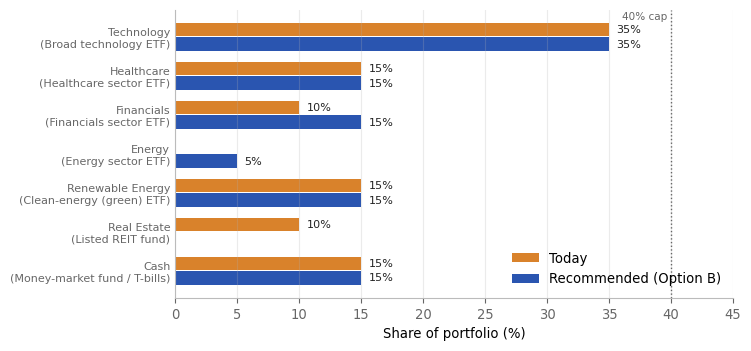

In [11]:
fig, ax = plt.subplots(figsize=(7.6, 3.6))
rows = np.arange(len(ASSETS))
BAR_HEIGHT = 0.38
for weights, offset, color, label in [(CURRENT_WEIGHTS, -BAR_HEIGHT / 2, CURRENT_COLOR, "Today"),
                                      (RECOMMENDED_WEIGHTS, BAR_HEIGHT / 2, RECOMMENDED_COLOR, f"Recommended ({recommended_label})")]:
    bars = ax.barh(rows + offset, 100 * weights, height=BAR_HEIGHT - 0.04, color=color, label=label)
    for bar, weight in zip(bars, 100 * weights):
        if weight > 0:
            ax.text(weight + 0.6, bar.get_y() + bar.get_height() / 2, f"{weight:.0f}%", va="center",
                    fontsize=8, color=TEXT_COLOR)
ax.set_yticks(rows, [f"{asset}\n({products.loc[asset, 'Product']})" for asset in ASSETS], fontsize=8)
ax.invert_yaxis()
ax.tick_params(axis="y", length=0)
ax.set_xlabel("Share of portfolio (%)")
ax.set_xlim(0, 45)
ax.axvline(40, color=MUTED_COLOR, ls=":", lw=1)
ax.text(39.7, -0.45, "40% cap", fontsize=7.5, color=MUTED_COLOR, ha="right")
ax.grid(axis="x", alpha=0.25)
ax.legend(loc="lower right", frameon=False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "s3_fig_allocation.pdf", bbox_inches="tight")
plt.show()

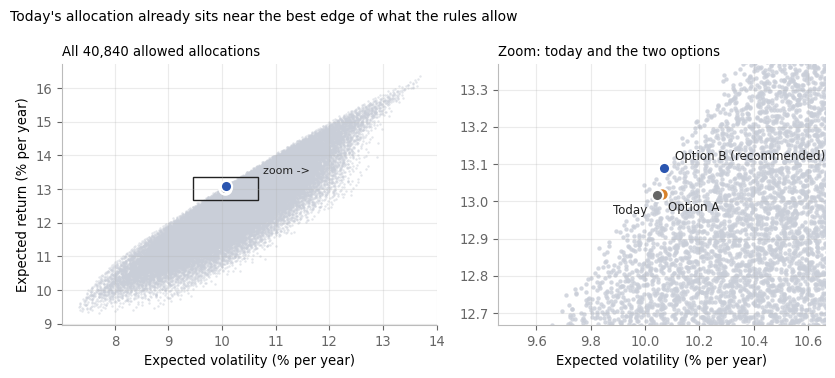

In [12]:
fig, (full_ax, zoom_ax) = plt.subplots(1, 2, figsize=(8.6, 3.8), gridspec_kw={"width_ratios": [1.15, 1]})
ZOOM_VOL, ZOOM_RETURN = 0.6, 0.35                       # half-width of the zoomed window around today
for ax in (full_ax, zoom_ax):
    ax.scatter(expected_volatility, expected_return, s=3 if ax is full_ax else 10, color="#C9CED8",
               alpha=0.5 if ax is full_ax else 0.8, lw=0, rasterized=True)
    ax.scatter(current_volatility, current_return, s=80, color=CURRENT_COLOR, zorder=3, edgecolor="white", lw=1.5)
    for label, index in [("Option A", option_a_index), ("Option B", option_b_index)]:
        marker_color = RECOMMENDED_COLOR if label == recommended_label else MUTED_COLOR
        ax.scatter(expected_volatility[index], expected_return[index], s=65, color=marker_color, zorder=3,
                   edgecolor="white", lw=1.5)
    ax.set_xlabel("Expected volatility (% per year)")
    ax.grid(alpha=0.25)
full_ax.set_ylabel("Expected return (% per year)")
full_ax.set_title(f"All {len(candidate_weights):,} allowed allocations", loc="left", fontsize=9.5)
full_ax.add_patch(plt.Rectangle((current_volatility - ZOOM_VOL, current_return - ZOOM_RETURN), 2 * ZOOM_VOL,
                                2 * ZOOM_RETURN, fill=False, ec=TEXT_COLOR, lw=1))
full_ax.annotate("zoom ->", (current_volatility + ZOOM_VOL, current_return + ZOOM_RETURN), xytext=(4, 2),
                 textcoords="offset points", fontsize=8, color=TEXT_COLOR)

zoom_ax.set_xlim(current_volatility - ZOOM_VOL, current_volatility + ZOOM_VOL)
zoom_ax.set_ylim(current_return - ZOOM_RETURN, current_return + ZOOM_RETURN)
zoom_ax.set_title("Zoom: today and the two options", loc="left", fontsize=9.5)
labels = [("Today", current_volatility, current_return, (-10, -14), "right")]
labels += [(label + (" (recommended)" if label == recommended_label else ""), expected_volatility[index],
            expected_return[index], offset, "left")
           for label, index, offset in [("Option A", option_a_index, (8, -12)), ("Option B", option_b_index, (8, 6))]]
for text, x, y, offset, align in labels:
    zoom_ax.annotate(text, (x, y), xytext=offset, textcoords="offset points", fontsize=8.5, color=TEXT_COLOR, ha=align)
fig.suptitle("Today's allocation already sits near the best edge of what the rules allow", x=0.01, ha="left", fontsize=10)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "s3_fig_frontier.pdf", bbox_inches="tight", dpi=200)
plt.show()

## 9. Check on the actual year, and key findings (computed, not typed)

In [13]:
actual_returns = market[[f"{sector} (%)" for sector in SECTORS]].to_numpy()[None]
actual_rate, actual_vix = market["policy_rate_pct"].to_numpy()[None], market["vix"].to_numpy()[None]
actual_year = {}
for label, weights in [("Today", CURRENT_WEIGHTS), ("Recommended", RECOMMENDED_WEIGHTS)]:
    weekly_returns, _, _ = run_policy(actual_returns, actual_rate, actual_vix, "Monthly rebalance", weights)
    annual_return, _, max_drawdown = yearly_metrics(weekly_returns)
    actual_year[label] = (annual_return[0], max_drawdown[0])

recommended_test = paired_tests.loc[recommended_label]
breach = "Chance of breaching 10% drawdown (%)"
trades = recommendation.loc[recommendation["Trade (pts)"].abs() > 1e-9, "Trade (pts)"]
rate_move = decision_criteria.loc["Portfolio move per +100 bp, true model (%)"]
findings = [
    f"{len(candidate_weights):,} allocations respect every client rule; today's allocation already sits near the best edge.",
    f"Option A (rule fixed in advance): {describe(OPTION_A_WEIGHTS)}; option B (safety first): {describe(OPTION_B_WEIGHTS)} "
    f"(order: {' / '.join(ASSETS)}).",
    (f"On 5,000 new years, A and B are statistically tied ({a_vs_b_z:+.1f} standard errors), so the one needing less trading wins: "
     if statistically_tied else
     f"On 5,000 new years, {recommended_label} beats the other option by {abs(a_vs_b_z):.1f} standard errors: ")
    + f"recommended {recommended_label}, which needs {decision_criteria.loc['One-way trading needed (pts)', recommended_label]:.0f} pts "
    f"of one-way trading vs {decision_criteria.loc['One-way trading needed (pts)'].drop(['Today', recommended_label]).iloc[0]:.0f}.",
    "Trades: " + ", ".join(f"{asset} {gap:+.0f} pts" for asset, gap in trades.items()) + ".",
    f"Versus today: return {recommended_test['Avg return gain vs today (pts)']:+.2f} pts a year "
    f"({recommended_test['Return gain / standard error']:+.1f} standard errors); breach chance "
    f"{validation.loc['Today - monthly rebalance', breach]:.1f}% -> {validation.loc[recommended_label + ' - monthly rebalance', breach]:.1f}%, "
    f"{validation.loc[recommended_label + ' - rebalance + risk triggers', breach]:.1f}% with the Stage 2 triggers.",
    f"A +100 bp rate rise: {rate_move['Today']:+.2f}% -> {rate_move[recommended_label]:+.2f}%; "
    f"Technology's share of risk {decision_criteria.loc['Technology share of risk (%)', 'Today']:.0f}% -> "
    f"{decision_criteria.loc['Technology share of risk (%)', recommended_label]:.0f}%.",
    f"On the actual year: today {actual_year['Today'][0]:+.1f}% (max drawdown {actual_year['Today'][1]:.1f}%), "
    f"recommended {actual_year['Recommended'][0]:+.1f}% (max drawdown {actual_year['Recommended'][1]:.1f}%).",
]
for finding in findings:
    print("-", finding)
(FIGURES_DIR / "s3_findings.txt").write_text("\n".join(findings))

- 40,840 allocations respect every client rule; today's allocation already sits near the best edge.
- Option A (rule fixed in advance): 30 / 40 / 10 / 0 / 15 / 0 / 5; option B (safety first): 35 / 15 / 15 / 5 / 15 / 0 / 15 (order: Technology / Healthcare / Financials / Energy / Renewable Energy / Real Estate / Cash).
- On 5,000 new years, Option B beats the other option by 2.6 standard errors: recommended Option B, which needs 10 pts of one-way trading vs 25.
- Trades: Financials +5 pts, Energy +5 pts, Real Estate -10 pts.
- Versus today: return +0.11 pts a year (+5.6 standard errors); breach chance 5.7% -> 5.6%, 4.1% with the Stage 2 triggers.
- A +100 bp rate rise: -1.90% -> -1.36%; Technology's share of risk 52% -> 52%.
- On the actual year: today +16.3% (max drawdown -3.0%), recommended +17.7% (max drawdown -3.5%).


816